# Coding Assignment 2: What can a traveller learn from a year of flights?

Data: 336,776 scheduled flights from Newark (EWR), Kennedy (JFK) and LaGuardia (LGA) in 2013,
from the U.S. Bureau of Transportation Statistics via `nycflights13`.
Run from this folder, with the two raw files in `data/`.

In [1]:
from pathlib import Path
import math
import pandas as pd
import plotnine as pn
from IPython.display import HTML, display

flights = pd.read_csv("data/flights.csv.zip")
airlines = pd.read_csv("data/airlines.csv")

## 1. Build the analysis sample

### (a) Rows, shapes, types and duplicates

* In `flights`, one row is **one scheduled flight**: one carrier's flight number leaving one
  New York airport on one date in 2013.
* In `airlines`, one row is **one airline**: a two-letter carrier code and its full name.

In [2]:
print("Flights shape:", flights.shape)
print("Airlines shape:", airlines.shape)
print("Type of arr_delay:", flights["arr_delay"].dtype)
print(flights[["year", "month", "day", "carrier", "flight", "origin", "arr_delay"]]
      .head(3).to_string(index=False))

Flights shape: (336776, 19)
Airlines shape: (16, 2)
Type of arr_delay: float64
 year  month  day carrier  flight origin  arr_delay
 2013      1    1      UA    1545    EWR       11.0
 2013      1    1      UA    1714    LGA       20.0
 2013      1    1      AA    1141    JFK       33.0


In [3]:
# Exact duplicates across all original columns
print("Exact duplicate flight rows:", flights.duplicated().sum())

# A flight number on its own is not a row ID: it recurs on different dates
print("Rows that repeat an earlier carrier + flight number:",
      flights.duplicated(subset=["carrier", "flight"]).sum())
print("Rows that repeat carrier + flight + date + origin:",
      flights.duplicated(subset=["year", "month", "day", "carrier", "flight", "origin"]).sum())

Exact duplicate flight rows: 0
Rows that repeat an earlier carrier + flight number: 331051
Rows that repeat carrier + flight + date + origin: 0


`arr_delay` is `float64`, so it is numeric. It is a float because missing values are stored as `NaN`.

There are **no exact duplicate rows**, so no rows need removing. The same carrier and flight
number appear many times, but on different dates. When we add the date and the origin
airport, every row is unique. These are different flights, not repeated records.
We also keep flights with a missing arrival delay. They are still scheduled flights (most were
cancelled or diverted), and we need them in Question 3(c).

### (b) Known and missing arrival delays, and the late-arrival indicator

In [4]:
known = flights["arr_delay"].notna().sum()
missing = flights["arr_delay"].isna().sum()
print("Known arrival delay:", known)
print("Missing arrival delay:", missing)
print("Known + missing:", known + missing, "| All flights:", len(flights))
assert known + missing == len(flights)

Known arrival delay: 327346
Missing arrival delay: 9430
Known + missing: 336776 | All flights: 336776


Rule: a flight is **late** when `arr_delay` is 15 minutes or more (1 = late, 0 = not late).
When `arr_delay` is missing, the indicator stays missing (`NaN`).

In [5]:
def late_indicator(delay):
    late = (delay >= 15).astype(float)
    return late.where(delay.notna())

flights["late"] = late_indicator(flights["arr_delay"])

# Check the rule on four test values
test = pd.DataFrame({"arr_delay": [-10, 14, 15, None]})
test["late"] = late_indicator(test["arr_delay"])
print(test.to_string(index=False))

 arr_delay  late
     -10.0   0.0
      14.0   0.0
      15.0   1.0
       NaN   NaN


In [6]:
print("Late flights:", int(flights["late"].sum()))
print("Missing late values:", flights["late"].isna().sum())
assert flights["late"].isna().sum() == missing

Late flights: 80100
Missing late values: 9430


An early arrival (−10) and 14 minutes give 0. Exactly 15 minutes gives 1.
A missing delay gives `NaN`, so it is not counted as on time or as late.

## 2. Attach the airline names

In [7]:
print("Each carrier code occurs once:", airlines["carrier"].is_unique)
assert airlines["carrier"].is_unique

rows_before = len(flights)
flights = flights.merge(
    airlines, on="carrier", how="left",
    validate="many_to_one",
)
rows_after = len(flights)
print("Rows before join:", rows_before)
print("Rows after join:", rows_after)
assert rows_before == rows_after

unmatched = flights["name"].isna().sum()
print("Flights with an unmatched carrier code:", unmatched)

Each carrier code occurs once: True
Rows before join: 336776
Rows after join: 336776
Flights with an unmatched carrier code: 0


Each code occurs once in the lookup, so the many-to-one join cannot multiply rows.
The row count is the same before and after the join, and every flight has an airline name.

## 3. Give the editor a table they can check

### (a) The five busiest airlines and all airlines combined

In [8]:
by_airline = flights.groupby("name", as_index=False).agg(
    scheduled=("flight", "size"),
    known_delay=("arr_delay", "count"),
    late=("late", "sum"),
)
assert by_airline["scheduled"].sum() == len(flights)

top5 = by_airline.sort_values("scheduled", ascending=False).head(5)

all_row = pd.DataFrame({
    "name": ["All airlines combined"],
    "scheduled": [len(flights)],
    "known_delay": [flights["arr_delay"].count()],
    "late": [flights["late"].sum()],
})

table = pd.concat([top5, all_row], ignore_index=True)
table["late"] = table["late"].astype(int)
table["pct_late"] = 100 * table["late"] / table["known_delay"]
print(table.to_string(index=False))

                    name  scheduled  known_delay  late  pct_late
   United Air Lines Inc.      58665        57782 13004 22.505278
         JetBlue Airways      54635        54049 14567 26.951470
ExpressJet Airlines Inc.      54173        51108 16399 32.086953
    Delta Air Lines Inc.      48110        47658  9038 18.964287
  American Airlines Inc.      32729        31947  6203 19.416534
   All airlines combined     336776       327346 80100 24.469522


In [9]:
view = table.rename(columns={
    "name": "Airline",
    "scheduled": "Scheduled flights",
    "known_delay": "Flights with known arrival delay",
    "late": "Late arrivals (15+ min)",
    "pct_late": "% late (of known)",
})
html_table = view.to_html(
    index=False,
    float_format=lambda number: f"{number:.1f}",
)
display(HTML(html_table))

Airline,Scheduled flights,Flights with known arrival delay,Late arrivals (15+ min),% late (of known)
United Air Lines Inc.,58665,57782,13004,22.5
JetBlue Airways,54635,54049,14567,27.0
ExpressJet Airlines Inc.,54173,51108,16399,32.1
Delta Air Lines Inc.,48110,47658,9038,19.0
American Airlines Inc.,32729,31947,6203,19.4
All airlines combined,336776,327346,80100,24.5


Only the displayed percentage is rounded. The stored `pct_late` keeps full precision.

### (b) Recompute one airline from the raw records

I check **United Air Lines Inc.** (carrier code `UA`). I filter the flight records and count
again, without using the `late` column or the summary table.

In [10]:
ua = flights.loc[flights["carrier"] == "UA"]
ua_known = ua["arr_delay"].notna().sum()
ua_late = (ua["arr_delay"] >= 15).sum()
ua_pct = 100 * ua_late / ua_known
print(f"United: {ua_late} late / {ua_known} known = {ua_pct:.1f}%")

table_pct = table.loc[table["name"] == "United Air Lines Inc.", "pct_late"].iloc[0]
print(f"Table value: {table_pct:.1f}%")
assert math.isclose(ua_pct, table_pct)

United: 13004 late / 57782 known = 22.5%
Table value: 22.5%


### (c) An alternative denominator: all scheduled flights

In [11]:
total = table.loc[table["name"] == "All airlines combined"].iloc[0]
headline = 100 * total["late"] / total["known_delay"]
alternative = 100 * total["late"] / total["scheduled"]
print(f"Headline rate:    {total['late']} / {total['known_delay']} = {headline:.1f}%")
print(f"Alternative rate: {total['late']} / {total['scheduled']} = {alternative:.1f}%")
print(f"Change: {alternative - headline:.1f} percentage points")

Headline rate:    80100 / 327346 = 24.5%
Alternative rate: 80100 / 336776 = 23.8%
Change: -0.7 percentage points


The alternative rate is about **0.7 percentage points lower**. Its denominator counts every
scheduled flight, including the 9,430 flights with no recorded arrival delay (mostly cancelled
or diverted). Those flights cannot be late in the numerator, so the alternative treats them as
if they arrived on time. This makes the late rate look better than the experience of
travellers whose flights actually arrived.

## 4. Pitch and illustrate your own finding

### (a) The pitch

**Reader:** a traveller who books a flight from New York and can choose the departure time.

**Question:** How does the chance of a late arrival change from morning to evening at each
of the three New York airports?

* **Measure:** percentage of flights that arrived 15 minutes or more late, among flights with a
  known arrival delay.
* **Flights included:** all 2013 flights with a known arrival delay, grouped by origin airport
  and scheduled departure hour (`hour`).
* **Cutoff:** I keep an airport-hour group only when it has at least 100 flights, so that each
  point is not based on a handful of flights.

In [12]:
known_flights = flights.dropna(subset=["arr_delay"]).copy()

by_hour = known_flights.groupby(["origin", "hour"], as_index=False).agg(
    flights=("late", "size"),
    late_rate=("late", "mean"),
)
by_hour["pct_late"] = 100 * by_hour["late_rate"]

small_groups = by_hour.loc[by_hour["flights"] < 100]
print("Groups dropped by the 100-flight cutoff:")
print(small_groups[["origin", "hour", "flights"]].to_string(index=False))

by_hour = by_hour.loc[by_hour["flights"] >= 100].copy()
print("Flights behind the figure:", by_hour["flights"].sum())

Groups dropped by the 100-flight cutoff:
origin  hour  flights
   EWR    22       61
   EWR    23       23
Flights behind the figure: 327262


In [13]:
airport_names = {
    "EWR": "Newark (EWR)",
    "JFK": "Kennedy (JFK)",
    "LGA": "LaGuardia (LGA)",
}
by_hour["airport"] = by_hour["origin"].map(airport_names)
print(by_hour.pivot(index="hour", columns="origin", values="pct_late").round(1).to_string())

origin   EWR   JFK   LGA
hour                    
5        8.9  10.7  14.4
6       12.0  13.4  10.5
7       13.6  11.1  10.9
8       19.1  15.1  14.7
9       18.1  18.1  15.4
10      18.2  18.2  19.1
11      17.0  17.8  19.8
12      22.0  18.5  21.1
13      25.1  20.3  23.9
14      29.7  24.9  25.1
15      33.3  28.9  28.2
16      33.7  26.0  32.2
17      36.9  29.4  34.4
18      38.7  29.4  32.9
19      42.3  31.6  32.8
20      38.3  33.9  32.3
21      39.4  38.8  32.7
22       NaN  34.0  31.9
23       NaN  30.1   NaN


### (b) and (c) The figure: first version and final version

**First version:** grouped (dodged) bars, one bar per airport for each hour.

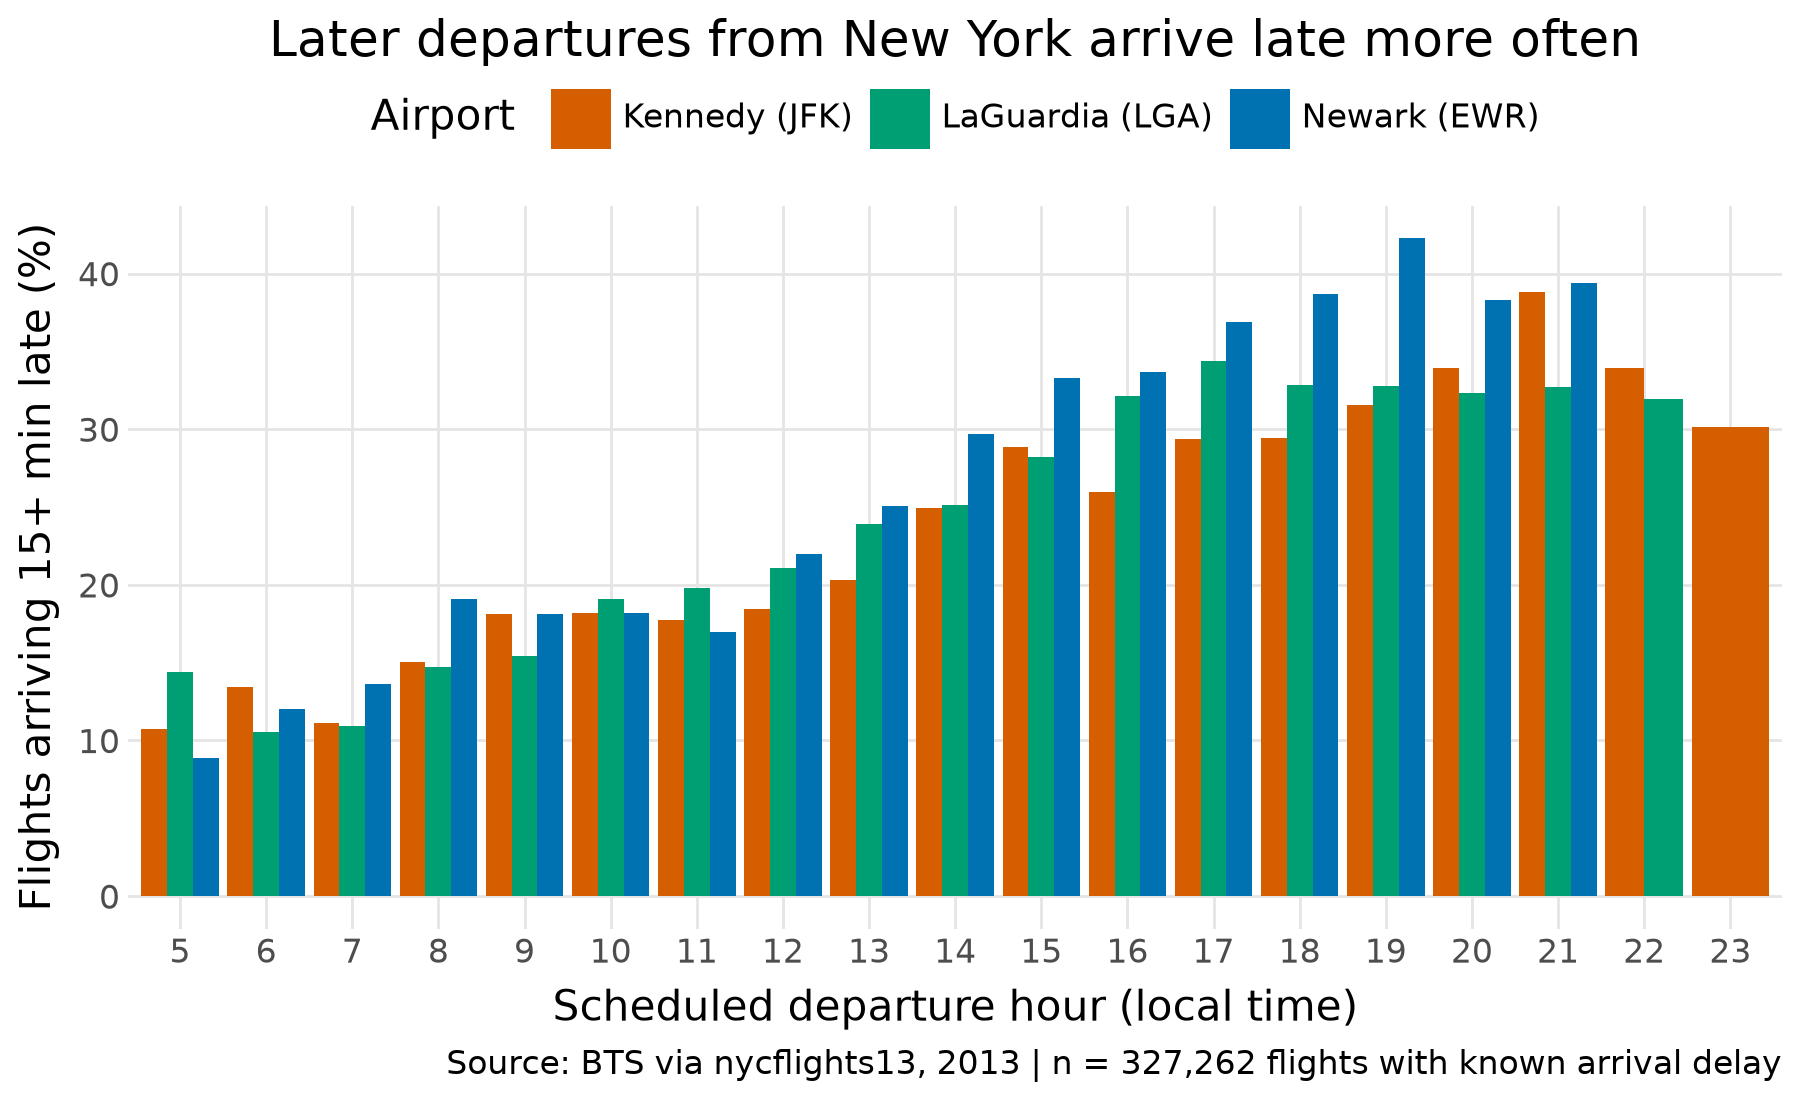

In [14]:
palette = {
    "Newark (EWR)": "#0072B2",
    "Kennedy (JFK)": "#D55E00",
    "LaGuardia (LGA)": "#009E73",
}
labels = pn.labs(
    title="Later departures from New York arrive late more often",
    x="Scheduled departure hour (local time)",
    y="Flights arriving 15+ min late (%)",
    caption=(
        "Source: BTS via nycflights13, 2013"
        f" | n = {by_hour['flights'].sum():,} flights with known arrival delay"
    ),
)
style = pn.theme_minimal(base_size=15) + pn.theme(
    figure_size=(9, 5.5),
    legend_position="top",
    panel_grid_minor=pn.element_blank(),
)

first = (
    pn.ggplot(by_hour, pn.aes("factor(hour)", "pct_late", fill="airport"))
    + pn.geom_col(position="dodge")
    + pn.scale_fill_manual(values=palette)
    + labels
    + pn.labs(fill="Airport")
    + style
)
first

**Final version:** one design decision changed. I replaced the dodged bars with
**lines and points**, one line per airport. Title, labels, colours and theme stay the same.

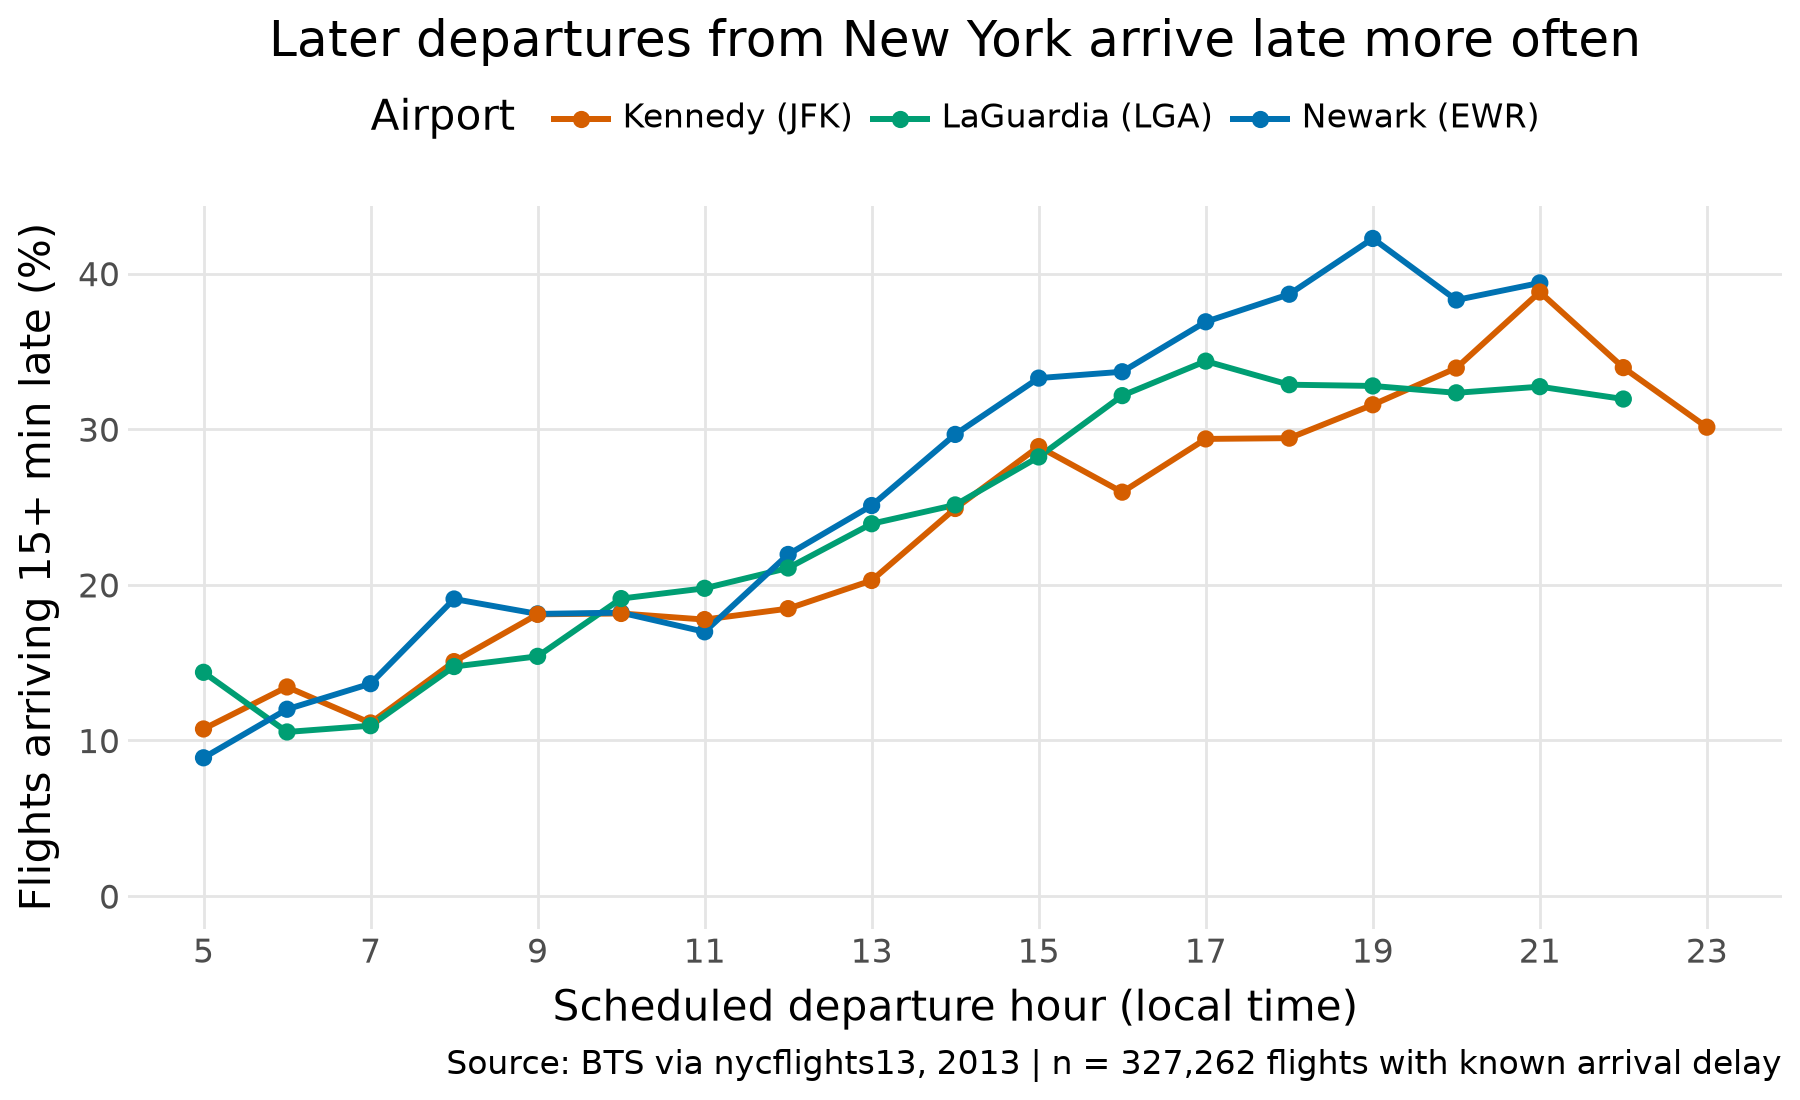

In [15]:
final = (
    pn.ggplot(by_hour, pn.aes("hour", "pct_late", color="airport"))
    + pn.geom_line(size=1.2)
    + pn.geom_point(size=2.5)
    + pn.scale_color_manual(values=palette)
    + pn.scale_x_continuous(breaks=range(5, 24, 2))
    + pn.expand_limits(y=0)
    + labels
    + pn.labs(color="Airport")
    + style
)
final

In [16]:
final.save("figure.png", width=9, height=5.5, dpi=200, verbose=False)
print(Path("figure.png").is_file())

True


**The edit.** With one line per airport, the reader sees at once that the late rate climbs
steadily from morning to evening at all three airports, and can follow each airport across
the day without comparing about 50 separate bars. The lines join hours that are separate groups,
so they suggest a smooth change between hours, and a reader can no longer compare bar heights
side by side within a single hour as easily.

### (d) The caption

In [17]:
morning = known_flights.loc[known_flights["hour"].between(5, 8)]
evening = known_flights.loc[known_flights["hour"].between(17, 21)]
morning_rate = morning.groupby("origin")["late"].mean() * 100
evening_rate = evening.groupby("origin")["late"].mean() * 100
compare = pd.DataFrame({
    "morning_5_to_8": morning_rate,
    "evening_17_to_21": evening_rate,
})
compare["ratio"] = compare["evening_17_to_21"] / compare["morning_5_to_8"]
print(compare.round(1).to_string())
print("Morning flights:", len(morning), "| Evening flights:", len(evening))

        morning_5_to_8  evening_17_to_21  ratio
origin                                         
EWR               14.6              38.9    2.7
JFK               13.4              31.7    2.4
LGA               12.0              33.2    2.8
Morning flights: 76596 | Evening flights: 91810


In [19]:
m, e = compare["morning_5_to_8"], compare["evening_17_to_21"]
caption = (
    "At all three New York airports, flights scheduled to leave in the evening "
    "arrived late far more often than morning flights. For departures between 17:00 "
    f"and 21:59, {e['EWR']:.0f}% of Newark, {e['JFK']:.0f}% of Kennedy and "
    f"{e['LGA']:.0f}% of LaGuardia flights arrived 15 or more minutes late, against "
    f"{m['EWR']:.0f}%, {m['JFK']:.0f}% and {m['LGA']:.0f}% for departures between "
    "05:00 and 08:59. Source: U.S. Bureau of Transportation Statistics via nycflights13, "
    "2013. Limit: this compares flights, not causes; evening flights may differ in "
    "airline, destination and season, and cancelled flights are excluded."
)
print(caption)
print("Words:", len(caption.split()))
assert 60 <= len(caption.split()) <= 100

At all three New York airports, flights scheduled to leave in the evening arrived late far more often than morning flights. For departures between 17:00 and 21:59, 39% of Newark, 32% of Kennedy and 33% of LaGuardia flights arrived 15 or more minutes late, against 15%, 13% and 12% for departures between 05:00 and 08:59. Source: U.S. Bureau of Transportation Statistics via nycflights13, 2013. Limit: this compares flights, not causes; evening flights may differ in airline, destination and season, and cancelled flights are excluded.
Words: 84
